In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os
import pandas as pd

sys.path.append(str(NB_DIR))

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pickle

from matal.configs import BATCH_DIR, PROJ_DIR, MODEL_DIR, DATA_DIR

In [2]:
file_path = DATA_DIR /'Distance_solubility_data.csv'
df = pd.read_csv(file_path)
display(df.describe())
print(df.columns)

,cons_ZnCl2(mol/kg),cons_ZnOTF2(mol/kg),ratio_MeOH(wt%),Unnamed: 5,Unnamed: 6
count,425.000000,425.000000,425.000000,0.0,0.0
mean,9.734353,1.711163,0.455771,NaN,NaN
std,8.529314,1.395604,0.324460,NaN,NaN
min,0.000000,0.000000,0.000000,NaN,NaN
25%,2.856147,0.545375,0.165275,NaN,NaN
50%,7.617649,1.565109,0.441964,NaN,NaN
75%,14.891900,2.652711,0.760077,NaN,NaN
max,33.500000,5.541128,1.000000,NaN,NaN


Index(['sample_sid', 'cons_ZnCl2(mol/kg)', 'cons_ZnOTF2(mol/kg)',
       'ratio_MeOH(wt%)', 'Solubility_+30', 'Unnamed: 5', 'Unnamed: 6'],
      dtype='object')


In [3]:
X = df[['cons_ZnCl2(mol/kg)', 'cons_ZnOTF2(mol/kg)', 'ratio_MeOH(wt%)']]
X_lims = np.array([35.0, 6.0, 1.0])
X_train_scaled = X / X_lims
y_train = df['Solubility_+30'].astype(int)

X_lims

array([35.,  6.,  1.])

In [4]:
file_path_test = DATA_DIR / 'Solubility_testingdata.csv' 
df_test = pd.read_csv(file_path_test)

display(df_test.describe())
print(df_test.columns)

# use the SAME feature columns
X_test = df_test[['cons_ZnCl2(mol/kg)', 'cons_ZnOTF2(mol/kg)', 'ratio_MeOH(wt%)']]

# IMPORTANT: use the SAME X_lims from training for scaling
X_test_scaled = X_test / X_lims

# same target column name
y_test = df_test['Solubility_+30'].astype(int)

X_test_ind = X_test_scaled
y_test_ind = y_test

,cons_ZnCl2(mol/kg),cons_ZnOTF2(mol/kg),ratio_MeOH(wt%),Unnamed: 5,Unnamed: 6
count,137.000000,137.000000,137.000000,0.0,0.0
mean,8.918635,1.718456,0.441085,NaN,NaN
std,7.495067,1.130654,0.320494,NaN,NaN
min,0.000000,0.000000,0.000000,NaN,NaN
25%,2.611365,0.877809,0.165189,NaN,NaN
50%,7.500000,1.565317,0.425651,NaN,NaN
75%,13.188050,2.500000,0.738975,NaN,NaN
max,30.298230,5.516399,1.000000,NaN,NaN


Index(['sample_sid', 'cons_ZnCl2(mol/kg)', 'cons_ZnOTF2(mol/kg)',
       'ratio_MeOH(wt%)', 'Solubility_+30', 'Unnamed: 5', 'Unnamed: 6'],
      dtype='object')


Best hyperparameters: OrderedDict([('C', 140.0088768497907), ('gamma', 2.6280407470185354)])
Best CV accuracy on training set: 0.9769435215946842

Training accuracy: 0.993
Independent test accuracy: 0.832

Classification report (independent test):
              precision    recall  f1-score   support

           0       1.00      0.60      0.75        58
           1       0.77      1.00      0.87        79

    accuracy                           0.83       137
   macro avg       0.89      0.80      0.81       137
weighted avg       0.87      0.83      0.82       137

Independent test ROC-AUC: 0.937


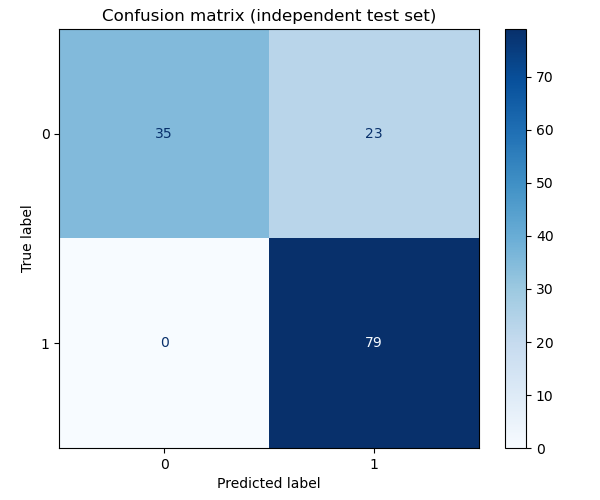

In [5]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from skopt import BayesSearchCV

search_space = {
    'C':     (1e-3, 1e+3, 'log-uniform'),
    'gamma': (1e-3, 1e+1, 'log-uniform'),
}

cv = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=5,
    random_state=0,
)

svc = SVC(kernel='rbf', probability=True)  

opt = BayesSearchCV(
    svc,
    search_space,
    n_iter=128,
    random_state=0,
    return_train_score=True,
    refit=True,          # refit best model on full TRAIN set
    cv=cv,
    n_jobs=8,
)

opt.fit(X_train_scaled, y_train)

print("Best hyperparameters:", opt.best_params_)
print("Best CV accuracy on training set:", opt.best_score_)


cv_results_df = pd.DataFrame(opt.cv_results_)
cv_results_df.to_csv("svm_cv_results_train_only.csv", index=False)

# Best trained model
best_svc = opt.best_estimator_

# =========================================
# 4. Standard evaluation
# =========================================
# ---- Training set performance (for overfitting check) ----
y_train_pred = best_svc.predict(X_train_scaled)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"\nTraining accuracy: {train_acc:.3f}")

# ---- Independent test set performance ----
y_test_pred = best_svc.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_test_pred)
print(f"Independent test accuracy: {test_acc:.3f}")

print("\nClassification report (independent test):")
print(classification_report(y_test, y_test_pred))

# ROC-AUC (binary classification assumed, positive class = 1)
y_test_proba = best_svc.predict_proba(X_test_scaled)[:, 1]
test_auc = roc_auc_score(y_test, y_test_proba)
print(f"Independent test ROC-AUC: {test_auc:.3f}")

# =========================================
# 5. Confusion matrix (independent test)
# =========================================
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(y_train))

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, colorbar=True)
ax.set_title("Confusion matrix (independent test set)")
plt.tight_layout()
plt.savefig("svm_confusion_matrix_independent_test.png", dpi=300)
plt.show()

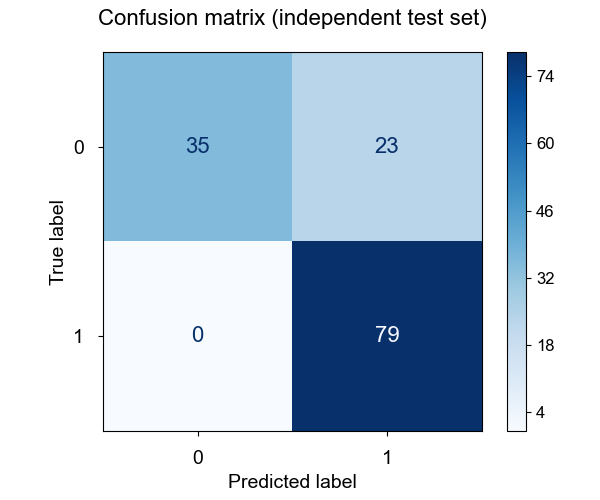

In [6]:
plt.rcParams["font.family"] = "Arial"

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(y_train))

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, colorbar=True)
ax.set_title("Confusion matrix (independent test set)")


for text in disp.text_.ravel():
    text.set_fontsize(16)         
    text.set_fontfamily("Arial")


ax.tick_params(axis="both", which="major", labelsize=14, pad = 10)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontfamily("Arial")


ax.set_xlabel("Predicted label", fontsize=14, fontfamily="Arial")
ax.set_ylabel("True label", fontsize=14, fontfamily="Arial")
ax.set_title("Confusion matrix (independent test set)",
             fontsize=16, fontfamily="Arial", pad=20)


cbar = disp.im_.colorbar
cbar.ax.tick_params(labelsize=12)
cbar.set_ticks([4, 18, 32, 46, 60, 74])
for t in cbar.ax.get_yticklabels():
    t.set_fontfamily("Arial")

plt.tight_layout()
#plt.savefig("svm_confusion_matrix_independent_test(grid & variance).png", dpi=300)
plt.show()

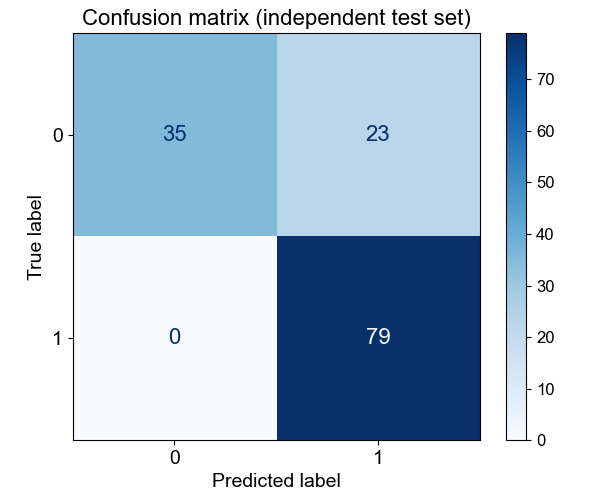

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Use Arial everywhere (falls back if not installed)
plt.rcParams["font.family"] = "Arial"

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(y_train))

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, colorbar=True)

# 2. Change font size / font of numbers in the cells
for text in disp.text_.ravel():
    text.set_fontsize(16)          # change number size here
    text.set_fontfamily("Arial")

# 3. Change tick label font size and font
ax.tick_params(axis="both", which="major", labelsize=14)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontfamily("Arial")

# 4. Axis labels and title
ax.set_xlabel("Predicted label", fontsize=14, fontfamily="Arial")
ax.set_ylabel("True label", fontsize=14, fontfamily="Arial")
ax.set_title("Confusion matrix (independent test set)",
             fontsize=16, fontfamily="Arial")

# 5. Colorbar tick labels
cbar = disp.im_.colorbar
cbar.ax.tick_params(labelsize=12)
for t in cbar.ax.get_yticklabels():
    t.set_fontfamily("Arial")

plt.tight_layout()
#lt.savefig("svm_confusion_matrix_independent_test.png", dpi=300)
plt.show()